# LAB 2 — Data Preprocessing Using Pandas

**Dataset:** USA Housing Dataset

### Requirements from the lab sheet
- Handle missing values.
- Remove duplicates.
- Encode categorical variables.
- Normalize datasets.
- Standardize datasets.

In [17]:
# 1. Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")


Libraries imported successfully.


In [18]:
# 2. Read the dataset independently

df = pd.read_csv("USA Housing Dataset.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (4140, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-09 00:00:00,"376,000.00",3.00,2.00,1340,1384,3.00,0,0,3,1340,0,2008,0,9245-9249 Fremont Ave N,Seattle,WA 98103,USA
1,2014-05-09 00:00:00,"800,000.00",4.00,3.25,3540,159430,2.00,0,0,3,3540,0,2007,0,33001 NE 24th St,Carnation,WA 98014,USA
2,2014-05-09 00:00:00,"2,238,888.00",5.00,6.50,7270,130017,2.00,0,0,3,6420,850,2010,0,7070 270th Pl SE,Issaquah,WA 98029,USA
3,2014-05-09 00:00:00,"324,000.00",3.00,2.25,998,904,2.00,0,0,3,798,200,2007,0,820 NW 95th St,Seattle,WA 98117,USA
4,2014-05-10 00:00:00,"549,900.00",5.00,2.75,3060,7015,1.00,0,0,5,1600,1460,1979,0,10834 31st Ave SW,Seattle,WA 98146,USA


In [19]:
# 5. Handle missing values

# Make a separate copy for preprocessing
data_clean = df.copy()

# Numerical columns: replace missing values with the median
numeric_cols = data_clean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if data_clean[col].isnull().any():
        data_clean[col] = data_clean[col].fillna(data_clean[col].median())

# Categorical columns: replace missing values with the mode
categorical_cols = data_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    if data_clean[col].isnull().any():
        data_clean[col] = data_clean[col].fillna(data_clean[col].mode()[0])

print("Missing values after handling:")
display(data_clean.isnull().sum())

print("Total missing values after handling:",
      data_clean.isnull().sum().sum())


Missing values after handling:


/tmp/ipykernel_10858/2814215007.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data_clean.select_dtypes(include="object").columns


date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

Total missing values after handling: 0


In [20]:
# 6. Check and remove duplicate rows

duplicates_before = data_clean.duplicated().sum()

print("Duplicate rows before removal:", duplicates_before)

data_clean = data_clean.drop_duplicates().reset_index(drop=True)

duplicates_after = data_clean.duplicated().sum()

print("Duplicate rows after removal:", duplicates_after)
print("Dataset shape after duplicate removal:", data_clean.shape)


Duplicate rows before removal: 0
Duplicate rows after removal: 0
Dataset shape after duplicate removal: (4140, 18)


## Feature preparation

Before encoding and scaling, we remove columns that are not useful for this preprocessing exercise and create a few simple features. This step is performed entirely inside Lab 2.


In [21]:
# 7. Feature preparation

processed_data = data_clean.copy()

# Convert date to datetime and extract useful parts
processed_data["date"] = pd.to_datetime(processed_data["date"])
processed_data["sale_year"] = processed_data["date"].dt.year
processed_data["sale_month"] = processed_data["date"].dt.month

# Feature engineering
processed_data["house_age"] = (
    processed_data["sale_year"] - processed_data["yr_built"]
)
processed_data["was_renovated"] = (
    processed_data["yr_renovated"] > 0
).astype(int)
processed_data["total_sqft"] = (
    processed_data["sqft_living"] +
    processed_data["sqft_basement"]
)

# Drop high-cardinality / constant columns for this preprocessing task
processed_data = processed_data.drop(
    columns=["date", "street", "country"]
)

print("Shape after feature preparation:", processed_data.shape)
display(processed_data.head())


Shape after feature preparation: (4140, 20)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip,sale_year,sale_month,house_age,was_renovated,total_sqft
0,"376,000.00",3.00,2.00,1340,1384,3.00,0,0,3,1340,0,2008,0,Seattle,WA 98103,2014,5,6,0,1340
1,"800,000.00",4.00,3.25,3540,159430,2.00,0,0,3,3540,0,2007,0,Carnation,WA 98014,2014,5,7,0,3540
2,"2,238,888.00",5.00,6.50,7270,130017,2.00,0,0,3,6420,850,2010,0,Issaquah,WA 98029,2014,5,4,0,8120
3,"324,000.00",3.00,2.25,998,904,2.00,0,0,3,798,200,2007,0,Seattle,WA 98117,2014,5,7,0,1198
4,"549,900.00",5.00,2.75,3060,7015,1.00,0,0,5,1600,1460,1979,0,Seattle,WA 98146,2014,5,35,0,4520


In [22]:
# 8. Separate features and target

X = processed_data.drop(columns=["price"])
y = processed_data["price"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())


Features:


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip,sale_year,sale_month,house_age,was_renovated,total_sqft
0,3.00,2.00,1340,1384,3.00,0,0,3,1340,0,2008,0,Seattle,WA 98103,2014,5,6,0,1340
1,4.00,3.25,3540,159430,2.00,0,0,3,3540,0,2007,0,Carnation,WA 98014,2014,5,7,0,3540
2,5.00,6.50,7270,130017,2.00,0,0,3,6420,850,2010,0,Issaquah,WA 98029,2014,5,4,0,8120
3,3.00,2.25,998,904,2.00,0,0,3,798,200,2007,0,Seattle,WA 98117,2014,5,7,0,1198
4,5.00,2.75,3060,7015,1.00,0,0,5,1600,1460,1979,0,Seattle,WA 98146,2014,5,35,0,4520


Target:


0     376,000.00
1     800,000.00
2   2,238,888.00
3     324,000.00
4     549,900.00
Name: price, dtype: float64

In [23]:
# 9. Split into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (3312, 19)
Testing set: (828, 19)


## Encoding categorical variables

Categorical columns such as `city` and `statezip` contain text. Machine-learning algorithms generally need numerical representations, so we use **One-Hot Encoding**.


In [24]:
# 10. Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'sale_year', 'sale_month', 'house_age', 'was_renovated', 'total_sqft']

Categorical features:
['city', 'statezip']


/tmp/ipykernel_10858/2208343536.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [25]:
# 11. One-Hot Encoding

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_train = encoder.fit_transform(
    X_train[categorical_features]
)

encoded_test = encoder.transform(
    X_test[categorical_features]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

encoded_train_df = pd.DataFrame(
    encoded_train,
    columns=encoded_columns,
    index=X_train.index
)

encoded_test_df = pd.DataFrame(
    encoded_test,
    columns=encoded_columns,
    index=X_test.index
)

print("Number of encoded categorical features:",
      len(encoded_columns))

display(encoded_train_df.head())


Number of encoded categorical features: 120


,city_Algona,city_Auburn,city_Beaux Arts Village,city_Bellevue,city_Black Diamond,city_Bothell,city_Burien,city_Carnation,city_Clyde Hill,city_Covington,city_Des Moines,city_Duvall,city_Enumclaw,city_Fall City,city_Federal Way,city_Issaquah,city_Kenmore,city_Kent,city_Kirkland,city_Lake Forest Park,city_Maple Valley,city_Medina,city_Mercer Island,city_Milton,city_Newcastle,city_Normandy Park,city_North Bend,city_Pacific,city_Preston,city_Ravensdale,city_Redmond,city_Renton,city_Sammamish,city_SeaTac,city_Seattle,city_Shoreline,city_Skykomish,city_Snoqualmie,city_Snoqualmie Pass,city_Tukwila,city_Vashon,city_Woodinville,city_Yarrow Point,statezip_WA 98001,statezip_WA 98002,statezip_WA 98003,statezip_WA 98004,statezip_WA 98005,statezip_WA 98006,statezip_WA 98007,statezip_WA 98008,statezip_WA 98010,statezip_WA 98011,statezip_WA 98014,statezip_WA 98019,statezip_WA 98022,statezip_WA 98023,statezip_WA 98024,statezip_WA 98027,statezip_WA 98028,statezip_WA 98029,statezip_WA 98030,statezip_WA 98031,statezip_WA 98032,statezip_WA 98033,statezip_WA 98034,statezip_WA 98038,statezip_WA 98039,statezip_WA 98040,statezip_WA 98042,statezip_WA 98045,statezip_WA 98047,statezip_WA 98050,statezip_WA 98051,statezip_WA 98052,statezip_WA 98053,statezip_WA 98055,statezip_WA 98056,statezip_WA 98057,statezip_WA 98058,statezip_WA 98059,statezip_WA 98065,statezip_WA 98068,statezip_WA 98070,statezip_WA 98072,statezip_WA 98074,statezip_WA 98075,statezip_WA 98077,statezip_WA 98092,statezip_WA 98102,statezip_WA 98103,statezip_WA 98105,statezip_WA 98106,statezip_WA 98107,statezip_WA 98108,statezip_WA 98109,statezip_WA 98112,statezip_WA 98115,statezip_WA 98116,statezip_WA 98117,statezip_WA 98118,statezip_WA 98119,statezip_WA 98122,statezip_WA 98125,statezip_WA 98126,statezip_WA 98133,statezip_WA 98136,statezip_WA 98144,statezip_WA 98146,statezip_WA 98148,statezip_WA 98155,statezip_WA 98166,statezip_WA 98168,statezip_WA 98177,statezip_WA 98178,statezip_WA 98188,statezip_WA 98198,statezip_WA 98199,statezip_WA 98288,statezip_WA 98354
3949,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3930,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
178,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
668,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0

## Normalization

**Min-Max Normalization** rescales numerical values to a fixed range, usually 0 to 1.


In [26]:
# 12. Normalize numerical features

minmax_scaler = MinMaxScaler()

X_train_normalized = pd.DataFrame(
    minmax_scaler.fit_transform(
        X_train[numeric_features]
    ),
    columns=numeric_features,
    index=X_train.index
)

X_test_normalized = pd.DataFrame(
    minmax_scaler.transform(
        X_test[numeric_features]
    ),
    columns=numeric_features,
    index=X_test.index
)

print("Normalized training data:")
display(X_train_normalized.head())

print("\nMinimum values in normalized training data:")
display(X_train_normalized.min().head())

print("\nMaximum values in normalized training data:")
display(X_train_normalized.max().head())


Normalized training data:


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,sale_year,sale_month,house_age,was_renovated,total_sqft
3949,0.43,0.04,0.09,0.00,0.20,0.00,0.00,0.50,0.10,0.03,0.39,1.00,0.00,0.00,0.61,1.00,0.07
3930,0.29,0.21,0.13,0.01,0.00,0.00,0.00,0.75,0.16,0.00,0.68,0.00,0.00,0.00,0.32,0.00,0.09
178,0.14,0.04,0.03,0.00,0.00,0.00,0.00,1.00,0.04,0.00,0.46,0.99,0.00,0.00,0.54,1.00,0.02
668,0.29,0.29,0.42,0.02,0.40,0.00,0.00,0.50,0.53,0.00,0.81,0.00,0.00,0.00,0.19,0.00,0.29
3330,0.43,0.33,0.19,0.01,0.00,0.00,0.00,0.75,0.09,0.23,0.54,0.00,0.00,1.00,0.46,0.00,0.21



Minimum values in normalized training data:


bedrooms      0.00
bathrooms     0.00
sqft_living   0.00
sqft_lot      0.00
floors        0.00
dtype: float64


Maximum values in normalized training data:


bedrooms      1.00
bathrooms     1.00
sqft_living   1.00
sqft_lot      1.00
floors        1.00
dtype: float64

## Standardization

**Standardization** transforms numerical features so that the training data has approximately mean 0 and standard deviation 1.


In [27]:
# 13. Standardize numerical features

standard_scaler = StandardScaler()

X_train_standardized = pd.DataFrame(
    standard_scaler.fit_transform(
        X_train[numeric_features]
    ),
    columns=numeric_features,
    index=X_train.index
)

X_test_standardized = pd.DataFrame(
    standard_scaler.transform(
        X_test[numeric_features]
    ),
    columns=numeric_features,
    index=X_test.index
)

print("Standardized training data:")
display(X_train_standardized.head())

print("\nMeans after standardization:")
display(X_train_standardized.mean().round(2).head())

print("\nStandard deviations after standardization:")
display(X_train_standardized.std().round(2).head())


Standardized training data:


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,sale_year,sale_month,house_age,was_renovated,total_sqft
3949,0.66,-1.48,-0.87,-0.26,-0.04,-0.09,-0.31,-0.66,-0.78,-0.35,-0.88,1.24,0.00,-1.27,0.88,1.22,-0.81
3930,-0.45,-0.22,-0.53,-0.13,-0.98,-0.09,-0.31,0.83,-0.23,-0.67,0.20,-0.82,0.00,-1.27,-0.20,-0.82,-0.66
178,-1.55,-1.48,-1.50,-0.26,-0.98,-0.09,-0.31,2.31,-1.31,-0.67,-0.65,1.22,0.00,-1.27,0.65,1.22,-1.42
668,-0.45,0.41,2.39,0.29,0.90,-0.09,-0.31,-0.66,3.02,-0.67,0.70,-0.82,0.00,-1.27,-0.70,-0.82,1.61
3330,0.66,0.73,0.05,-0.14,-0.98,-0.09,-0.31,0.83,-0.85,1.70,-0.31,-0.82,0.00,1.73,0.31,-0.82,0.68



Means after standardization:


bedrooms      -0.00
bathrooms      0.00
sqft_living   -0.00
sqft_lot      -0.00
floors         0.00
dtype: float64


Standard deviations after standardization:


bedrooms      1.00
bathrooms     1.00
sqft_living   1.00
sqft_lot      1.00
floors        1.00
dtype: float64

## Combine the preprocessed features

The final ML-ready dataset combines standardized numerical features with one-hot encoded categorical features.


In [28]:
# 14. Create final preprocessed training and testing data

X_train_processed = pd.concat(
    [X_train_standardized, encoded_train_df],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_standardized, encoded_test_df],
    axis=1
)

print("Final processed training shape:",
      X_train_processed.shape)

print("Final processed testing shape:",
      X_test_processed.shape)

display(X_train_processed.head())


Final processed training shape: (3312, 137)
Final processed testing shape: (828, 137)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,sale_year,sale_month,house_age,was_renovated,total_sqft,city_Algona,city_Auburn,city_Beaux Arts Village,city_Bellevue,city_Black Diamond,city_Bothell,city_Burien,city_Carnation,city_Clyde Hill,city_Covington,city_Des Moines,city_Duvall,city_Enumclaw,city_Fall City,city_Federal Way,city_Issaquah,city_Kenmore,city_Kent,city_Kirkland,city_Lake Forest Park,city_Maple Valley,city_Medina,city_Mercer Island,city_Milton,city_Newcastle,city_Normandy Park,city_North Bend,city_Pacific,city_Preston,city_Ravensdale,city_Redmond,city_Renton,city_Sammamish,city_SeaTac,city_Seattle,city_Shoreline,city_Skykomish,city_Snoqualmie,city_Snoqualmie Pass,city_Tukwila,city_Vashon,city_Woodinville,city_Yarrow Point,statezip_WA 98001,statezip_WA 98002,statezip_WA 98003,statezip_WA 98004,statezip_WA 98005,statezip_WA 98006,statezip_WA 98007,statezip_WA 98008,statezip_WA 98010,statezip_WA 98011,statezip_WA 98014,statezip_WA 98019,statezip_WA 98022,statezip_WA 98023,statezip_WA 98024,statezip_WA 98027,statezip_WA 98028,statezip_WA 98029,statezip_WA 98030,statezip_WA 98031,statezip_WA 98032,statezip_WA 98033,statezip_WA 98034,statezip_WA 98038,statezip_WA 98039,statezip_WA 98040,statezip_WA 98042,statezip_WA 98045,statezip_WA 98047,statezip_WA 98050,statezip_WA 98051,statezip_WA 98052,statezip_WA 98053,statezip_WA 98055,statezip_WA 98056,statezip_WA 98057,statezip_WA 98058,statezip_WA 98059,statezip_WA 98065,statezip_WA 98068,statezip_WA 98070,statezip_WA 98072,statezip_WA 98074,statezip_WA 98075,statezip_WA 98077,statezip_WA 98092,statezip_WA 98102,statezip_WA 98103,statezip_WA 98105,statezip_WA 98106,statezip_WA 98107,statezip_WA 98108,statezip_WA 98109,statezip_WA 98112,statezip_WA 98115,statezip_WA 98116,statezip_WA 98117,statezip_WA 98118,statezip_WA 98119,statezip_WA 98122,statezip_WA 98125,statezip_WA 98126,statezip_WA 98133,statezip_WA 98136,statezip_WA 98144,statezip_WA 98146,statezip_WA 98148,statezip_WA 98155,statezip_WA 98166,statezip_WA 98168,statezip_WA 98177,statezip_WA 98178,statezip_WA 98188,statezip_WA 98198,statezip_WA 98199,statezip_WA 98288,statezip_WA 98354
3949,0.66,-1.48,-0.87,-0.26,-0.04,-0.09,-0.31,-0.66,-0.78,-0.35,-0.88,1.24,0.00,-1.27,0.88,1.22,-0.81,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3930,-0.45,-0.22,-0.53,-0.13,-0.98,-0.09,-0.31,0.83,-0.23,-0.67,0.20,-0.82,0.00,-1.27,-0.20,-0.82,-0.66,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
178,-1.55,-1.48,-1.50,-0.26,-0.98,-0.09,-0.31,2.31,-1.31,-0.67,-0.65,1.22,0.00,-1.27,0.65,1.22,-1.42,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0

## Visualize preprocessing

A simple comparison makes the effect of normalization and standardization easier to understand.


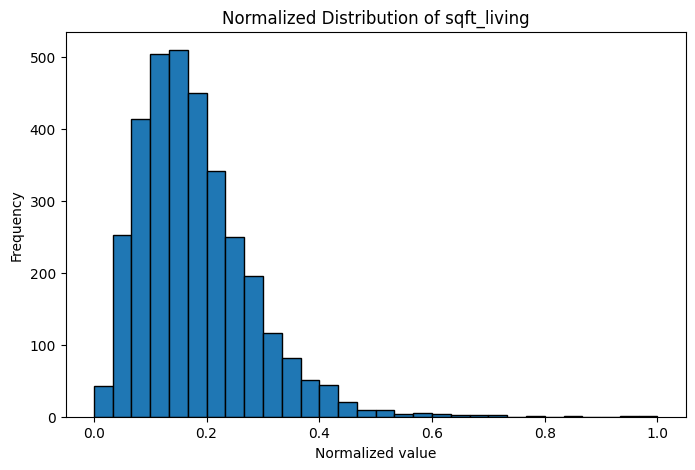

In [29]:
# 15. Original vs normalized distribution

feature = "sqft_living"



plt.figure(figsize=(8, 5))
plt.hist(X_train_normalized[feature], bins=30, edgecolor="black")
plt.xlabel("Normalized value")
plt.ylabel("Frequency")
plt.title("Normalized Distribution of sqft_living")
plt.show()


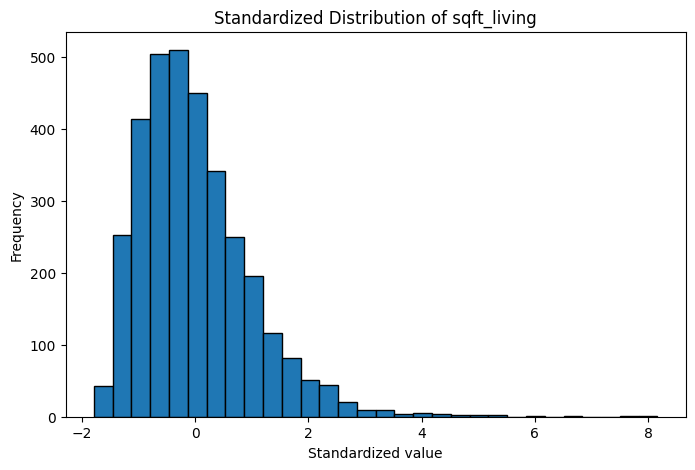

In [30]:
# 16. Original vs standardized distribution

plt.figure(figsize=(8, 5))
plt.hist(X_train_standardized[feature], bins=30, edgecolor="black")
plt.xlabel("Standardized value")
plt.ylabel("Frequency")
plt.title("Standardized Distribution of sqft_living")
plt.show()


## Lab 2 Conclusion

The USA Housing dataset was independently loaded and prepared. Missing values were checked and handled, duplicate records were removed, categorical variables were one-hot encoded, and numerical variables were normalized and standardized. The final data was converted into an ML-ready numerical form without depending on Lab 1.
